##### Advanced Statistical Analysis and Model-Based Learning (Fall 2026-2027)
# Home Assignment 2

#### Topics:
- Probability review
- Normal, Chi-Squared, t, and F distributions
- Distributional Properties of the Linear Model
- Solving LS using SVD

#### Due: 23/11/2026 by 18:30


#### Instructions:
- Write your IDs and date at the top cell.
- Submit a copy of this notebook with code filled in the relevant places as the solution of coding exercises.
- For theoretic exercises, you can either write your solution in the notebook using $\LaTeX$ (preffered) or submit additional notes.


**ID1**: 342681004 

**ID2**: 207884883

**Date**: 18.11.2026

<hr>
<hr>

## Problem 1 (Conditional Expectation)
Let $X$ and $Y$ be two random variables with a probability model $P_{X,Y}$. Let $m : \mathbb R \to \mathbb R$ such that $m(X)$ and $f(X)$ are random variables with finite variance. Suppose that $m(X)$ satisfies the ``orthogonality principle``: for any function $f : \mathbb R \to \mathbb R$ such that $f(X)$ is a random variable,
$$
\mathbb E \left[\left(Y - m(X) \right) f(X) \right] = 0.
$$
Namely, the error in predicting the target is ``orthogonal`` to the data. Prove that
$$
\mathbb E \left[\left(Y - m(X) \right)^2 \right] \leq \mathbb E \left[ \left(Y - f(X) \right)^2 \right].
$$

**Answer**:

**Reminder:** The orthogonality principle states that the best or optimal approximation of a target with a subspace occurs when the error vector is perpendicular /  orthogonal to every vector in that subspace.

Let's first develop the expression $Y-f(X)$. This expression is equivalent to $(Y-m(X)) + (m(X)- f(X))$.
If we apply the same development to $E[(Y-f(X))^2]$ we get:
$$
\begin{align*}
E[(Y-f(X))^2]   &= E[((Y-m(X)) + (m(X)- f(X)))^2] \\
                &= E[(Y-m(X))^2 + (m(X)-f(X))^2 + 2(Y-m(X))(m(X)-f(X))] \\
                &= E[(Y-m(X))^2] + E[(m(X)-f(X))^2] + 2E[(Y-m(X))(m(X)-f(X))] 
\end{align*}
$$
by linearity of expectations.


Let's define $g(X) = m(X) - f(X)$. 

Since m(X) and f(X) are random variables, g(X) is also a random variable. Applying the orthogonality principle to g gives $E[(Y-m(X))(m(X)-f(X))] = E[(Y-m(X))g(X)] = 0$.

Thus: $E[(Y-f(X))^2] = E[(Y-m(X))^2] + E[(m(X)-f(X))^2]$

Since $(m(X)-f(X))^2 \geq 0$ everywhere, monotonicity of expectation ensures that $E[(m(X) - f(X))^2] \geq 0$. Dropping this non-negative term gives
$$E[(Y - m(X))^2] \leq E[(Y - f(X))^2]$$
with equality holding if and only if $f(X) = m(X)$ almost surely.

# Problem 2 (Sampling from $\mathcal N(0,1)$, $\chi^2$, $t$, and $F$)
In the following exercise, you can only sample using repeated calls to ``random.random()``.
You can use the ``scipy.stats`` package *only* to illustrate PDFs. You should illustrate histograms with number of bins about 5%-10% of the number of samples $n=1,000$ in the input to the histogram. For example, use $100$ bins equally spaced between the range of the samples, so that you'll get a nice comparison between the empirical distribution and the theoretical distribution represented by the PDF. Make sure that the histogram is normalized to approximate the density of the simulated random variable. Set the seed ``random.seed(my_id)`` where ``my_id`` is your ID number with leading zeros removed.

1. Implement the functions ``sample_unif``, ``sample_normal_clt``, and ``sample_normal``. Illustrate the histogram of $1000$ samples from ``sample_normal_clt`` and $1000$ samples from ``sample_normal``. Choose the input to ``sample_normal_clt`` so that the two histogram look alike.
2. Implement the functions ``sample_chisq``, ``sample_t``, and ``sample_f``. You should use ``sample_normal`` repeatedly.
3. Use ``sample_normal`` to sample $1000$ times from $\mathcal N(0,1)$ and use one figure to illustrate the histogram of the samples and the true PDF of $\mathcal N(0,1)$
4. Use ``sample_chisq`` to sample $1000$ times from $\chi^2_k$ and use one figure to illustrate the histogram of the samples and the true PDF of $\chi^2_k$; for $k=4$ and $k=12$.
5. Use ``sample_t`` to sample $1000$ times from $t_k$ (the $t$-distribution with $k$ degrees of freedom) and use one figure to illustrate the histogram of the samples and the true PDF of $t_k$; for $k=4$ and $k=12$.
6. Use ``sample_F`` to sample $1000$ times from $F_{k_1,k_2}$ and use one figure to illustrate the histogram of the samples and the true PDF of $F_{k_1,k_2}$; for $(k_1, k_2)= (8,6)$ and $(k_1, k_2)= (40,35)$.

In [1]:
import random
from scipy.stats import norm
import numpy as np

def sample_unif(n: int) -> list[float]:
    """
    n independent samples from the uniform distribution over (0,1)
    """

    # YOUR CODE HERE
    samples = [random.random() for i in range(n)]
    return samples


def sample_normal_clt(n: int) -> float:
    """
    Use the CLT to approximately sample from the standard normal distribution

    Args:
        n:    number of samples from a non-normal distribution

    Returns:
        z:    a random sample, approximately from the standard normal distribution

    """

    # YOUR CODE HERE
    samples = sample_unif(n)
    return float(np.sqrt(12 * n) * (np.mean(samples) - 0.5))

def sample_normal() -> float:
    """
    Sample from the standard normal distribution using a single sample
    from the uniform distribution. You should use the normal quantile function
    ``norm.ppf``

    Return:
        z:    a random sample from the standard normal distribution

    """

    # YOUR CODE HERE
    u = random.random()
    while u == 0:
        u = random.random()
    return float(norm.ppf(u))


def sample_chisq(k: int) -> float:
    """
    Sample from the chisquared distribution with k degrees of freedom

    Args:
        k:    number of degrees of freedom (DoF)

    Return:
        x:    random sample from the chisquared distribution with k degrees of freedom

    """

    # YOUR CODE HERE
    samples = sum(sample_normal()**2 for i in range(k))
    return float(samples)


def sample_t(k: int) -> float:
    """
    Sample from the t distribution with k degrees of freedom

    Args:
        k:    number of degrees of freedom

    Return:
        x:    random sample from the t distribution

    """

    # YOUR CODE HERE
    numerator = sample_normal()
    denominator = np.sqrt(sample_chisq(k)/k)
    return float(numerator / denominator)


def sample_f(k1: int, k2:int) -> float:
    """
    Sample from the F distribution with k1 over k2 degrees of freedom

    Args:
        k1:    number of degrees of freedom numerator
        k2:    number of degrees of freedom denominator

    Return:
        x:    random sample from the F distribution

    """

    # YOUR CODE HERE
    numerator = sample_chisq(k1) / k1
    denominator = sample_chisq(k2) / k2
    return float(numerator / denominator)

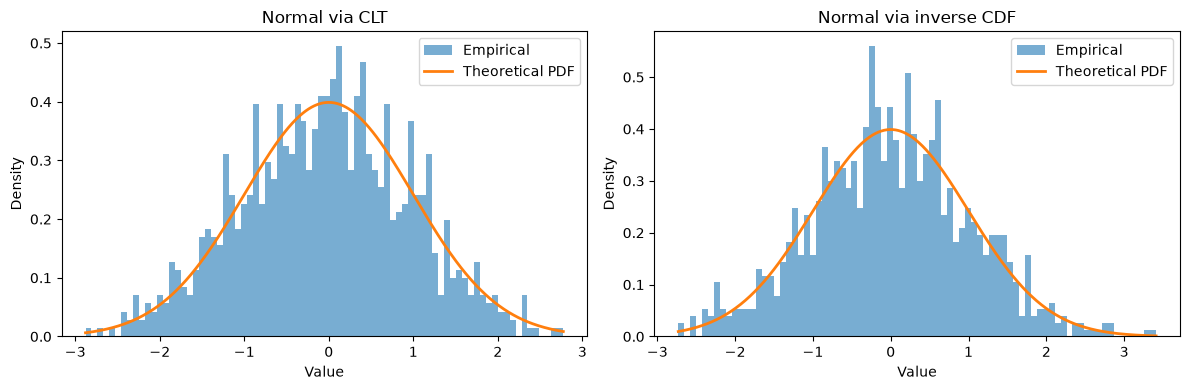

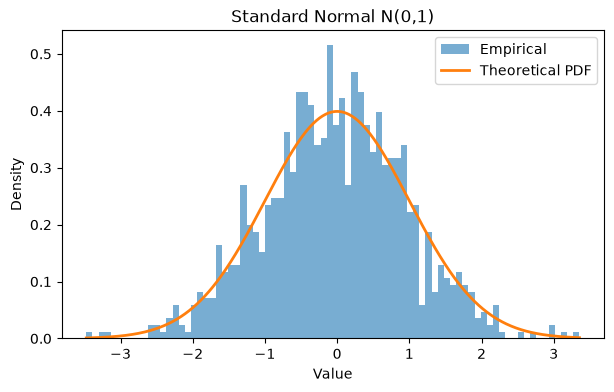

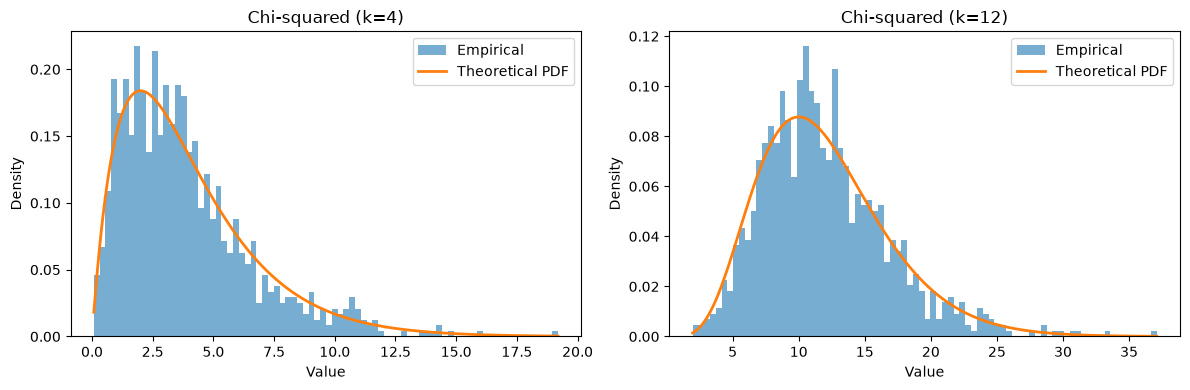

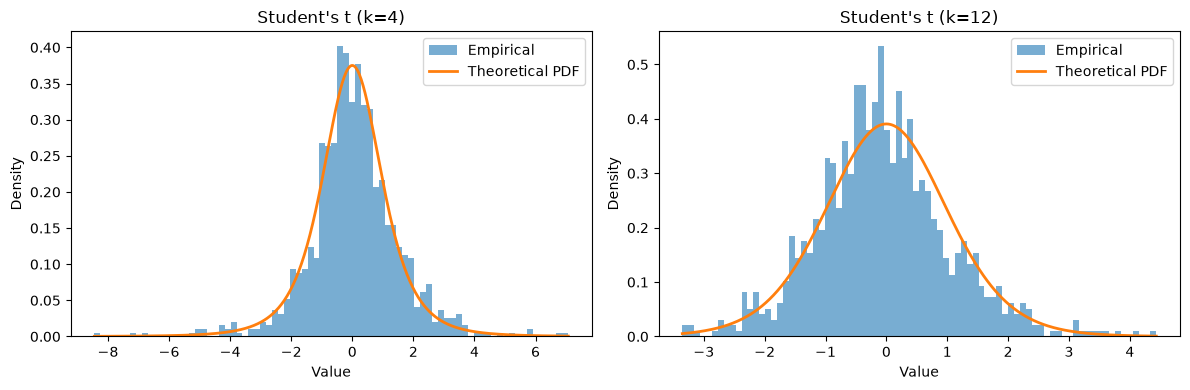

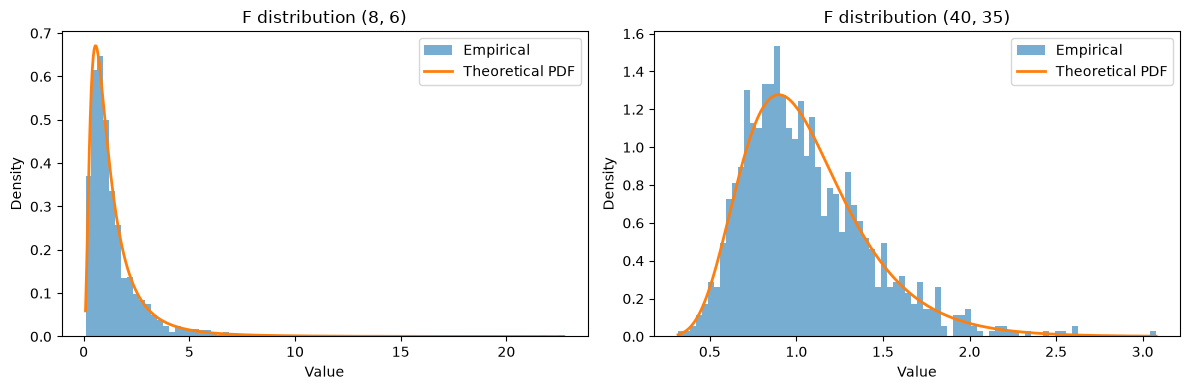

In [2]:
MY_ID = 342681004 # your personal ID number with leading zeros removed
random.seed(MY_ID)

# Your code to items 2-4 goes here:

import matplotlib.pyplot as plt
from scipy.stats import norm, chi2, t, f


def plot_distribution(samples, pdf, title, ax):
    bins = np.linspace(min(samples), max(samples), 81)
    x = np.linspace(min(samples), max(samples), 500)

    ax.hist(samples, bins=bins, density=True,
            alpha=0.6, label="Empirical")
    ax.plot(x, pdf(x), linewidth=2, label="Theoretical PDF")

    ax.set_title(title)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()


# Part 1: Compare CLT-based sampling with inverse transform
n_clt = 100

clt_samples = [sample_normal_clt(n_clt) for _ in range(1000)]
normal_samples = [sample_normal() for _ in range(1000)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, samples, title in zip(
    axes,
    [clt_samples, normal_samples],
    ["Normal via CLT", "Normal via inverse CDF"]
):
    plot_distribution(samples, norm.pdf, title, ax)

plt.tight_layout()
plt.show()


# Part 3: Standard normal
samples = [sample_normal() for _ in range(1000)]

fig, ax = plt.subplots(figsize=(7, 4))
plot_distribution(samples, norm.pdf, "Standard Normal N(0,1)", ax)
plt.show()


# Part 4: Chi-squared, k=4 and k=12
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, k in zip(axes, [4, 12]):
    samples = [sample_chisq(k) for _ in range(1000)]
    plot_distribution(samples, chi2(k).pdf, f"Chi-squared (k={k})", ax)

plt.tight_layout()
plt.show()


# Part 5: Student's t, k=4 and k=12
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, k in zip(axes, [4, 12]):
    samples = [sample_t(k) for _ in range(1000)]
    plot_distribution(samples, t(k).pdf, f"Student's t (k={k})", ax)

plt.tight_layout()
plt.show()


# Part 6: F distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (k1, k2) in zip(axes, [(8, 6), (40, 35)]):
    samples = [sample_f(k1, k2) for _ in range(1000)]
    plot_distribution(
        samples, f(k1, k2).pdf,
        f"F distribution ({k1}, {k2})", ax
    )

plt.tight_layout()
plt.show()


**Choice of $n$ for `sample_normal_clt`.** The uniform distribution is symmetric with bounded
support, so the standardized mean converges to $\mathcal N(0,1)$ quickly (already $n=12$
is a classical approximation). With $n=100$ the CLT histogram is practically indistinguishable
from the inverse-CDF histogram, as seen in the first figure.

## Problem 3 (The Normal Distribution)

1. Let $Z = (Z_1,\ldots,Z_9)^\top \sim \mathcal N(\mu, I_9)$ where $\mu \in \reals^9$. Show that $3Z_1-Z_2+Z_3-Z_4$ is independent of $Z_1 + Z_2 - Z_3 + Z_4 - Z_5$.

2. Suppose that $Z \sim \mathcal N(\mu, I_n)$ and let $X = a^\top Z$ and $Y = B^\top Z$ for a non-random vectors $a \in \mathbb R^n$ and a non-random matrix $B \in \mathbb R^{n \times p}$. Find conditions on $a$ and $B$ such that $X$ is independent of $Y$.

3. Suppose that $Z_{ij} \overset{iid}{\sim} \mathcal N(0, 1)$ for $i= 1,\ldots,I$ and $j=1,\ldots,J$. Define
$$
\bar{Z}_{i\bullet} := \frac{1}{J} \sum_{j=1}^J Z_{ij},\qquad \bar{Z}_{\bullet j} := \frac{1}{I} \sum_{i=1}^I Z_{ij}, \qquad \bar{Z}_{\bullet \bullet} := \frac{1}{IJ} \sum_{j=1}^J \sum_{i=1}^I Z_{ij}
$$

- Is $\bar{Z}_{i\bullet}$ independent of $\bar{Z}_{\bullet j}$ ?
- Is $\bar{Z}_{1\bullet}$ independent of $\bar{Z}_{2\bullet}$ ?
- Is $\bar{Z}_{i\bullet} - \bar{Z}_{\bullet \bullet}$ independent of $\bar{Z}_{i\bullet}$ ?

4. Consider the variance-covariance matrix
$$
\bar{\Sigma} = \begin{bmatrix} 1 & 0.4 \\
0.4 & 1
\end{bmatrix}
$$
Using as many samples as you need from the standard normal distribution (e.g. ``numpy.random.randn``), generate $N = 1000$ independent samples from the bivariate normal distribution $\mathcal N(0, \bar{\Sigma})$ (you'll get $N$ pairs). Illustrate these samples over a scatter plot.

5. Consider the region in $\reals^2$:
$$
A = \{ (x,y)\,: 0 \leq x \leq 1, 2x \leq y \leq 3\}
$$
For $(X_1, X_2) \sim \mathcal N(0, \bar{\Sigma})$, estimate
$$
\Pr\left[ (X_1, X_2) \in A \right]
$$
in two ways:
    1. Evaluating the integral over the Gaussian density function **numerically**. Set the number of grid points $G$ in every axis to be at least $500$.
    2. Estimating the fraction of samples in 4 that falls in the region $A$


**ANSWERS**:

**1. Independence of the two linear combinations**

Let $U=3Z_1-Z_2+Z_3-Z_4$ and $V=Z_1+Z_2-Z_3+Z_4-Z_5$. Their coefficient vectors are
$$
a=(3,-1,1,-1,0,0,0,0,0)^\top,
\qquad b=(1,1,-1,1,-1,0,0,0,0)^\top.
$$
Thus $U=a^\top Z$ and $V=b^\top Z$. Since $\operatorname{Cov}(Z)=I_9$,
$$
\operatorname{Cov}(U,V)=a^\top I_9b=a^\top b=3-1-1-1=0.
$$
The pair $(U,V)$ is jointly Gaussian because it is a linear transformation of the Gaussian vector $Z$. For jointly Gaussian variables, zero covariance implies independence, so **$U$ and $V$ are independent**. The value of $\mu$ does not affect this conclusion.

**2. Conditions on $a$ and $B$**

The vector $(X,Y^\top)^\top$ is jointly Gaussian, with cross-covariance
$$
\operatorname{Cov}(X,Y)=a^\top\operatorname{Cov}(Z)B=a^\top B\in\mathbb R^{1\times p}.
$$
Therefore the necessary and sufficient condition is
$$
\boxed{X\perp\!\!\!\perp Y\quad\Longleftrightarrow\quad a^\top B=0_{1\times p}
\quad\Longleftrightarrow\quad B^\top a=0_p.}
$$
Equivalently, $a$ must be orthogonal to every column of $B$, or $a\in\operatorname{Null}(B^\top)$. No full-rank assumption on $B$ is needed.

**3. Independence of the sample means**

All the means and differences below are jointly Gaussian, because they are linear combinations of the independent normal observations. Their covariance must be calculated: linear combinations of independent observations can share observations and need not have zero covariance.

- **$\bar Z_{i\bullet}$ and $\bar Z_{\bullet j}$ are not independent.** We have
  $$
  \operatorname{Cov}(\bar Z_{i\bullet},\bar Z_{\bullet j})
  =\frac{1}{IJ}\sum_{k=1}^J\sum_{\ell=1}^I
  \operatorname{Cov}(Z_{ik},Z_{\ell j})=\frac{1}{IJ}>0.
  $$
  Only the term with $k=j$ and $\ell=i$ is nonzero; it is $\operatorname{Var}(Z_{ij})=1$.

- **$\bar Z_{1\bullet}$ and $\bar Z_{2\bullet}$ are independent** (assuming $I\geq2$ so both rows exist). They involve disjoint sets of independent observations, and
  $$
  \operatorname{Cov}(\bar Z_{1\bullet},\bar Z_{2\bullet})
  =\frac{1}{J^2}\sum_{j=1}^J\sum_{k=1}^J
  \operatorname{Cov}(Z_{1j},Z_{2k})=0.
  $$
  Joint Gaussianity then implies independence.

- **$\bar Z_{i\bullet}-\bar Z_{\bullet\bullet}$ and $\bar Z_{i\bullet}$ are not independent when $I>1$.** First,
  $$
  \operatorname{Var}(\bar Z_{i\bullet})=\frac{1}{J},\qquad
  \bar Z_{\bullet\bullet}=\frac{1}{I}\sum_{\ell=1}^I\bar Z_{\ell\bullet}.
  $$
  Since different row means are independent,
  $$
  \operatorname{Cov}(\bar Z_{\bullet\bullet},\bar Z_{i\bullet})
  =\frac{1}{I}\operatorname{Var}(\bar Z_{i\bullet})=\frac{1}{IJ}.
  $$
  Hence
  $$
  \boxed{\operatorname{Cov}(\bar Z_{i\bullet}-\bar Z_{\bullet\bullet},\bar Z_{i\bullet})
  =\frac{1}{J}-\frac{1}{IJ}=\frac{I-1}{IJ}.}
  $$
  This is positive for $I>1$, so the variables are dependent. In the special case $I=1$, the difference is identically zero and is independent of the row mean.


**4. Generate and plot 1,000 bivariate normal samples**

A Cholesky factor of $\bar\Sigma$ is
$$
L=\begin{bmatrix}1&0\\0.4&\sqrt{1-0.4^2}\end{bmatrix},
\qquad LL^\top=\bar\Sigma.
$$
For independent $U,V\sim\mathcal N(0,1)$, set
$$
X_1=U,\qquad X_2=0.4U+\sqrt{0.84}\,V.
$$
This is a Gaussian vector with mean zero, both marginal variances equal to one, and covariance $0.4$. Independent standard normal pairs give independent samples. The code uses a fixed seed for reproducibility; it also marks which samples fall in the region from part 5.


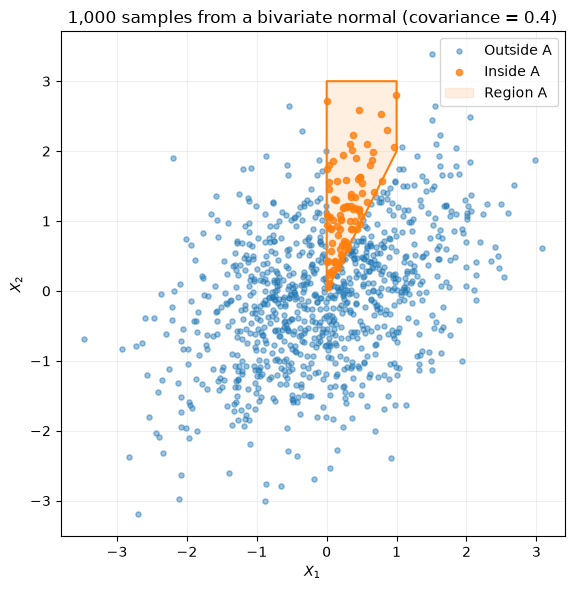

Sample mean: [-0.03537701 -0.00909034]
Sample covariance matrix:
 [[1.07867122 0.41578971]
 [0.41578971 0.99778291]]


In [3]:
import numpy as np
import matplotlib.pyplot as plt

rng_q3 = np.random.default_rng(342681004)
N = 1000
Sigma_q3 = np.array([[1.0, 0.4], [0.4, 1.0]])
L_q3 = np.linalg.cholesky(Sigma_q3)
standard_normals_q3 = rng_q3.standard_normal((N, 2))
samples_q3 = standard_normals_q3 @ L_q3.T
x1_q3, x2_q3 = samples_q3.T

in_A_q3 = (
    (x1_q3 >= 0) & (x1_q3 <= 1)
    & (x2_q3 >= 2 * x1_q3) & (x2_q3 <= 3)
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(x1_q3[~in_A_q3], x2_q3[~in_A_q3],
           s=14, alpha=0.45, label="Outside A")
ax.scatter(x1_q3[in_A_q3], x2_q3[in_A_q3],
           s=20, alpha=0.8, color="tab:orange", label="Inside A")
ax.fill([0, 1, 1, 0], [0, 2, 3, 3], color="tab:orange",
        alpha=0.12, label="Region A")
ax.plot([0, 1, 1, 0, 0], [0, 2, 3, 3, 0],
        color="tab:orange", linewidth=1.5)
ax.set(xlabel=r"$X_1$", ylabel=r"$X_2$",
       title="1,000 samples from a bivariate normal (covariance = 0.4)")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

print("Sample mean:", samples_q3.mean(axis=0))
print("Sample covariance matrix:\n", np.cov(samples_q3, rowvar=False))


**5. Estimate $\Pr[(X_1,X_2)\in A]$ in two ways**

The density is
$$
f(x,y)=\frac{1}{2\pi\sqrt{0.84}}
\exp\!\left(-\frac{x^2-0.8xy+y^2}{2(0.84)}\right),
$$
so the required probability is
$$
p=\int_0^1\int_{2x}^{3}f(x,y)\,dy\,dx.
$$

1. **Numerical integration:** use $G=1001\geq500$ grid points for $x\in[0,1]$. For each $x$, use $G$ grid points for $y\in[2x,3]$, and apply the trapezoidal rule first in $y$ and then in $x$. Matching the inner grid to the sloping boundary integrates over the specified region directly.
2. **Sample fraction:** use the same $N=1000$ samples generated in part 4 and calculate
   $$
   \widehat p_{\mathrm{MC}}=\frac{1}{1000}\sum_{r=1}^{1000}
   \mathbf{1}\{0\leq X_1^{(r)}\leq1,\;2X_1^{(r)}\leq X_2^{(r)}\leq3\}.
   $$
   Its estimated Monte Carlo standard error is $\sqrt{\widehat p_{\mathrm{MC}}(1-\widehat p_{\mathrm{MC}})/1000}$, which explains why it need not equal the numerical integral exactly.


In [4]:
from scipy.integrate import trapezoid

G = 1001
x_grid_q3 = np.linspace(0.0, 1.0, G)
t_grid_q3 = np.linspace(0.0, 1.0, G)
# Each column contains G y values from 2*x to 3 for a fixed x.
y_grid_q3 = (
    2 * x_grid_q3[None, :]
    + (3 - 2 * x_grid_q3[None, :]) * t_grid_q3[:, None]
)
x_mesh_q3 = x_grid_q3[None, :]
density_q3 = np.exp(
    -(x_mesh_q3**2 - 0.8 * x_mesh_q3 * y_grid_q3 + y_grid_q3**2)
    / (2 * 0.84)
) / (2 * np.pi * np.sqrt(0.84))

integral_y_q3 = trapezoid(density_q3, x=y_grid_q3, axis=0)
p_grid_q3 = trapezoid(integral_y_q3, x=x_grid_q3)
count_A_q3 = np.count_nonzero(in_A_q3)
p_mc_q3 = count_A_q3 / N
mc_se_q3 = np.sqrt(p_mc_q3 * (1 - p_mc_q3) / N)

print(f"Numerical integral (G = {G} per axis): {p_grid_q3:.8f}")
print(f"Sample fraction: {count_A_q3}/{N} = {p_mc_q3:.6f}")
print(f"Estimated Monte Carlo standard error: {mc_se_q3:.6f}")
print(f"Absolute difference between estimates: {abs(p_mc_q3 - p_grid_q3):.6f}")


Numerical integral (G = 1001 per axis): 0.08058161
Sample fraction: 88/1000 = 0.088000
Estimated Monte Carlo standard error: 0.008959
Absolute difference between estimates: 0.007418


For this fixed seed, the numerical integral is **0.08058161**, while the sample fraction is **88/1000 = 0.088**. The Monte Carlo standard error is approximately **0.0090**. The estimates differ by about **0.83** estimated standard errors, which is consistent with sampling variation.


## Problem 4 (Conditional Distribution)
For
$$
\begin{bmatrix}
X \\
Y \\
Z
\end{bmatrix} \sim \mathcal N\left( \begin{bmatrix} 1 \\
2\\
3
\end{bmatrix}, \begin{bmatrix}
 4 & -1 & 3 \\
 -1 & 2 & -3 \\
 3 & -3 & 8
\end{bmatrix}
\right)
$$
find (numerically):
1. The distribution of $X$ given that $Y = 1$.
2. The joint distribution of $X$ and $Y$ given $Z = 1$.
3. The distribution of $Y$ given that $Z = 2$ and $X = 3$.
4. $Pr(Y \in [-1,1] | Z=4, X=3)$
<hr>
<hr>

### 4 — Conditional Gaussian distributions

We use $\mathcal N(\mu,\sigma^2)$, with **variance** as the second argument.
Partition the jointly Gaussian vector into a target block $A$ and an observed block $B$.
The conditional distribution is Gaussian with
$$\mu_{A\mid B=b}=\mu_A+\Sigma_{AB}\Sigma_{BB}^{-1}(b-\mu_B),$$
$$\Sigma_{A\mid B}=\Sigma_{AA}-\Sigma_{AB}\Sigma_{BB}^{-1}\Sigma_{BA}.$$
These are the formulas from the probability-review slides, "Conditional Distributions."
Observing $B=b$ updates the target mean and reduces its covariance. The conditional
covariance does not depend on the particular value $b$.

#### 4.1 — $X\mid Y=1$

Here $\mu_X=1$, $\mu_Y=2$, $\Sigma_{XY}=-1$, and $\operatorname{Var}(Y)=2$. Hence
$$\mu_{X\mid Y=1}=1+\frac{-1}{2}(1-2)=\frac32,$$
$$\sigma^2_{X\mid Y}=4-\frac{(-1)^2}{2}=\frac72.$$
Thus $\boxed{X\mid Y=1\sim\mathcal N(1.5,3.5).}$

#### 4.2 — $(X,Y)^\top\mid Z=1$

Take $A=(X,Y)^\top$ and $B=Z$. Then
$$\mu_{A\mid Z=1}=\begin{pmatrix}1\\2\end{pmatrix}
+\frac18\begin{pmatrix}3\\-3\end{pmatrix}(1-3)
=\begin{pmatrix}1/4\\11/4\end{pmatrix},$$
$$\Sigma_{A\mid Z}=\begin{pmatrix}4&-1\\-1&2\end{pmatrix}
-\frac18\begin{pmatrix}3\\-3\end{pmatrix}\begin{pmatrix}3&-3\end{pmatrix}
=\begin{pmatrix}23/8&1/8\\1/8&7/8\end{pmatrix}.$$
Therefore
$$\boxed{\begin{pmatrix}X\\Y\end{pmatrix}\Bigm|Z=1\sim
\mathcal N_2\!\left(\begin{pmatrix}0.25\\2.75\end{pmatrix},
\begin{pmatrix}2.875&0.125\\0.125&0.875\end{pmatrix}\right).}$$

#### 4.3 — $Y\mid Z=2,X=3$

Keep the observed block in the order $B=(Z,X)^\top$:
$$\mu_B=\begin{pmatrix}3\\1\end{pmatrix},\quad
\Sigma_{BB}=\begin{pmatrix}8&3\\3&4\end{pmatrix},\quad
\Sigma_{YB}=\begin{pmatrix}-3&-1\end{pmatrix}.$$
Its inverse is $\Sigma_{BB}^{-1}=\frac1{23}\begin{pmatrix}4&-3\\-3&8\end{pmatrix}$,
so $\Sigma_{YB}\Sigma_{BB}^{-1}=\begin{pmatrix}-9/23&1/23\end{pmatrix}$.
Consequently,
$$\mu_{Y\mid Z=2,X=3}=2+\begin{pmatrix}-9/23&1/23\end{pmatrix}
\begin{pmatrix}-1\\2\end{pmatrix}=\frac{57}{23},$$
$$\sigma^2_{Y\mid Z,X}=2-\begin{pmatrix}-9/23&1/23\end{pmatrix}
\begin{pmatrix}-3\\-1\end{pmatrix}=\frac{20}{23}.$$
Thus $\boxed{Y\mid Z=2,X=3\sim\mathcal N(2.47826087,0.86956522).}$

#### 4.4 — $\Pr(-1\leq Y\leq1\mid Z=4,X=3)$

The covariance blocks are unchanged, but now $b-\mu_B=(1,2)^\top$. Thus
$$Y\mid Z=4,X=3\sim\mathcal N\!\left(\frac{39}{23},\frac{20}{23}\right).$$
Writing $\Phi$ for the standard-normal CDF gives
$$\boxed{\Pr(-1\leq Y\leq1\mid Z=4,X=3)
=\Phi\!\left(\frac{1-39/23}{\sqrt{20/23}}\right)
-\Phi\!\left(\frac{-1-39/23}{\sqrt{20/23}}\right)
\approx0.22591102.}$$
The CDF calculation uses the conditional **standard deviation**, $\sqrt{20/23}$.

In [5]:
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

mu_q4 = np.array([1., 2., 3.])  # order: X, Y, Z
Sigma_q4 = np.array([[4., -1., 3.], [-1., 2., -3.], [3., -3., 8.]])

def conditional_gaussian(mu, covariance, target, observed, observed_values):
    target = np.asarray(target, dtype=int)
    observed = np.asarray(observed, dtype=int)
    AA = covariance[np.ix_(target, target)]
    AB = covariance[np.ix_(target, observed)]
    BB = covariance[np.ix_(observed, observed)]
    delta = np.asarray(observed_values, dtype=float) - mu[observed]
    conditional_mean = mu[target] + AB @ np.linalg.solve(BB, delta)
    conditional_covariance = AA - AB @ np.linalg.solve(BB, AB.T)
    return conditional_mean, conditional_covariance

mean_41, cov_41 = conditional_gaussian(mu_q4, Sigma_q4, [0], [1], [1.])
mean_42, cov_42 = conditional_gaussian(mu_q4, Sigma_q4, [0, 1], [2], [1.])
mean_43, cov_43 = conditional_gaussian(mu_q4, Sigma_q4, [1], [2, 0], [2., 3.])
mean_44, cov_44 = conditional_gaussian(mu_q4, Sigma_q4, [1], [2, 0], [4., 3.])
conditional_probability_q4 = (
    stats.norm.cdf(1., loc=mean_44[0], scale=np.sqrt(cov_44[0, 0]))
    - stats.norm.cdf(-1., loc=mean_44[0], scale=np.sqrt(cov_44[0, 0]))
)

display(pd.DataFrame({
    'distribution': ['X | Y=1', 'Y | Z=2, X=3', 'Y | Z=4, X=3'],
    'mean': [mean_41[0], mean_43[0], mean_44[0]],
    'variance': [cov_41[0, 0], cov_43[0, 0], cov_44[0, 0]],
}))
print('Mean of (X,Y) | Z=1:', mean_42)
print('Covariance of (X,Y) | Z=1:\n', cov_42)
print(f'P(-1 <= Y <= 1 | Z=4, X=3) = {conditional_probability_q4:.8f}')

,distribution,mean,variance
0,X | Y=1,1.500000,3.500000
1,"Y | Z=2, X=3",2.478261,0.869565
2,"Y | Z=4, X=3",1.695652,0.869565


Mean of (X,Y) | Z=1: [0.25 2.75]
Covariance of (X,Y) | Z=1:
 [[2.875 0.125]
 [0.125 0.875]]
P(-1 <= Y <= 1 | Z=4, X=3) = 0.22591102


## Problem 5 (Distributional Properties of the Least Squares Estiamte)
Consider a least squares model with one predictor $p=1$ without an intercept term, i.e. $y_i = \beta x_i + \epsilon_i$, $i=1,\ldots,n$.
1. Write the least squares solution $\hat{\beta} \in \mathbb R$ in terms of $x = (x_1,\ldots,x_n)^\top$ and $y = (y_1,\ldots,y_n)^\top$.
2. With $\hat{y}_i = \hat{\beta} x_i$ and $\hat{\epsilon}_i = y_i - \hat{y}_i$, show that
 - $\sum_{i=1}^n \hat{y}_i \hat{\epsilon}_i = 0$
 - $\|\hat{\epsilon}\|^2 = \|y\|^2 -  \|\hat{y}\|^2$
3. Suppose that $\epsilon_i \overset{iid}{\sim} N(0, 1)$.
 - What is the distribution of the random vector $[ \hat{\epsilon}~~ \hat{y}]^\top$?
 - What is the distribution of the random vector $[\hat{y}~~ \hat{\beta}]^\top$?
4. (bonus) Set $\|\epsilon\|_{\infty} := \max_{i=1,\ldots,n} |\epsilon_i|$. What is $Pr( \|\hat{\epsilon}\|_{\infty} > 2)$? is it larger or smaller than $Pr(\|\epsilon\|_{\infty}  > 2)$? (The point: we want to know if the predicted residuals tend to have less or more extreme values than the true ones)

<hr>
<hr>


### 5 — Least-squares estimates as Gaussian random variables

Assume the design vector $x\in\mathbb R^n$ is fixed and nonzero, and set $s=x^\top x>0$.
If the design is random, the results below are conditional on its observed value under
the stated Gaussian error model. This is the one-column case of the lecture's
$y=Z\beta+\epsilon$ model, with $Z=x$ and no intercept.

#### 5.1 — Least-squares coefficient

Differentiating $\|y-\beta x\|^2$ gives $-2x^\top y+2\beta x^\top x=0$, so
$$\boxed{\hat\beta=\frac{x^\top y}{s}.}$$
Define $H=xx^\top/s$. Then $\hat y=Hy$ and $\hat\epsilon=(I-H)y$.

#### 5.2 — Orthogonality and the squared-norm identity

Since $H^\top=H$ and $H^2=H$,
$$\sum_i\hat y_i\hat\epsilon_i=\hat y^\top\hat\epsilon
=y^\top H(I-H)y=y^\top(H-H^2)y=0.$$
Expanding $y=\hat y+\hat\epsilon$ therefore gives
$$\boxed{\|\hat\epsilon\|^2=\|y\|^2-\|\hat y\|^2.}$$
This is the same projection orthogonality used in Homework 1, now with a one-dimensional
fitted subspace.

#### 5.3 — Joint distributions under $\epsilon\sim\mathcal N_n(0,I_n)$

The model is $y=\beta x+\epsilon$. Because $Hx=x$,
$$\hat\epsilon=(I-H)\epsilon,\quad
\hat y=\beta x+H\epsilon,\quad
\hat\beta=\beta+\frac{x^\top\epsilon}{s}.$$
All three are affine transformations of the same Gaussian vector, so their joint
vectors are Gaussian. The required means and covariance blocks give
$$\boxed{\begin{pmatrix}\hat\epsilon\\\hat y\end{pmatrix}
\sim\mathcal N_{2n}\!\left(
\begin{pmatrix}0_n\\\beta x\end{pmatrix},
\begin{pmatrix}I-H&0_{n\times n}\\0_{n\times n}&H\end{pmatrix}
\right).}$$
The cross-covariance is $(I-H)H=0$, hence $\hat\epsilon$ and $\hat y$ are independent
by joint Gaussianity, as in the lecture's distributional-results theorem.
For the other requested vector,
$$\boxed{\begin{pmatrix}\hat y\\\hat\beta\end{pmatrix}
\sim\mathcal N_{n+1}\!\left(
\begin{pmatrix}\beta x\\\beta\end{pmatrix},
\begin{pmatrix}H&x/s\\x^\top/s&1/s\end{pmatrix}
\right).}$$
Here $\operatorname{Cov}(\hat y,\hat\beta)=x/s$ because $\hat y=x\hat\beta$.
Thus these two quantities are not independent. Both displayed Gaussian distributions
are singular: the first covariance has rank $n$, and the second has rank one.
A singular Gaussian distribution is still well defined by its mean and covariance.

#### 5.4 — Bonus: extreme residuals

Let $M=I-H$ and $C=[-2,2]^n$. The exact expression is
$$\boxed{\Pr(\|\hat\epsilon\|_\infty>2)
=1-\Pr\{G\in C\},\qquad G\sim\mathcal N_n(0,M).}$$
It depends on the design $x$ through $M$; there is no single numerical value without
specifying $x$ and $n$. For the original independent errors,
$$\boxed{\Pr(\|\epsilon\|_\infty>2)=1-[2\Phi(2)-1]^n.}$$
We can compare them rigorously using the Gaussian rectangle inequality of
[Šidák (1967), Corollary 1](https://www.math.toronto.edu/mccann/assignments/477/Sidak67.pdf):
for a centered Gaussian vector $G$, including singular Gaussian limits,
$$\Pr\{|G_i|\leq c_i\text{ for all }i\}\geq\prod_i\Pr\{|G_i|\leq c_i\}.$$
This is an additional result used for the bonus. Set $h_i=H_{ii}=x_i^2/s$, so
$\operatorname{Var}(\hat\epsilon_i)=1-h_i\in[0,1]$. Define
$$q_i=\Pr(|\hat\epsilon_i|\leq2)=
\begin{cases}2\Phi(2/\sqrt{1-h_i})-1,&h_i<1,\\1,&h_i=1.\end{cases}$$
Each $q_i\geq2\Phi(2)-1$, and at least one inequality is strict because $x\ne0$.
Consequently,
$$\Pr(\|\hat\epsilon\|_\infty\leq2)\geq\prod_iq_i>[2\Phi(2)-1]^n,$$
which proves
$$\boxed{\Pr(\|\hat\epsilon\|_\infty>2)
<\Pr(\|\epsilon\|_\infty>2).}$$
The residual coordinates are generally dependent, so their joint probability cannot
be replaced by a product as an equality. This is a probability comparison, not a claim
that every realized residual vector has smaller maximum norm than its error vector.

## Problem 6 (Model fitting, t- and F-Tests)
Consider the house prices dataset from the EDA notebook, which you can obtain from kaggle via:

**Data source used below.** The course code archive provides `housing_prices.csv`,
containing 1,460 houses and 81 columns, including `SalePrice` and every predictor
requested in Problems 6–7. A copy is included beside this notebook, and both problems
use this same course table. The original Kaggle download commands are replaced by
loading that local course file so a fresh run does not require Kaggle credentials.

In [6]:
from pathlib import Path
housing_path = Path('housing_prices.csv')
if not housing_path.is_file():
    housing_path = Path('Ex2') / 'housing_prices.csv'
if not housing_path.is_file():
    raise FileNotFoundError('Place the course housing_prices.csv beside this notebook.')

Only consider houses of lot size smaller than $15,000$ square feet, e.g. by using

In [7]:
import pandas as pd

data_raw = pd.read_csv(housing_path)
data = data_raw.loc[data_raw['LotArea'] < 15000].copy()

Consider predicting ``SalePrice`` via a linear model with predictors:

In [8]:
feat_set1 = ['LotArea',  'YearBuilt', 'YrSold', 'GarageCars',
             'FullBath', 'TotalBsmtSF', 'GarageArea', 'OverallQual']

plus a constant.

1. Find the least squares estimate $\hat{\beta}$ of this model.
2. Find $R^2$ of this model.
3. For each $\beta_j$, $j=1,\ldots,9$, evaluate the $t$ statistic corresponding to testing
$$
H_{0j}\,:\, \beta_j=0
$$
and its P-values (identify first the number of degrees of freedom).
4. Which of these statistics exceeds the $0.975$-th quantile of the corresponding $t$ distribution and below the $0.025$-th quantile? (values exceeding theses quantiles are strong evidence against $H_{0j}$)
5. Consider a smaller model involving only ``LotArea``,  ``YearBuilt``, ``YrSold`` as predictors. Find the least squares estimate of this smaller model and its sum of sqaures. Is this model provides a valid representation of the data compared to the original larger one? Answer your question by evaluating the relevant $F$ statistic and report on the F-test's P-value.

<hr>
<hr>

### 6 — Model fitting and inference

We use the Gaussian linear model $y=Z\beta+\epsilon$ with fixed full-column-rank $Z$
and $\epsilon\sim\mathcal N(0,\sigma^2I)$. The exact $t$ and $F$ reference distributions
below rely on these assumptions. These are model-based tests of conditional associations,
not causal effects.

#### 6.1–6.2 — Full model and $R^2$

Include a constant and all eight listed predictors, so there are $p=9$ coefficients.
For the retained houses,
$$\hat\beta=(Z^\top Z)^{-1}Z^\top y,\quad
SS_{full}=\|y-Z\hat\beta\|^2,\quad
R^2=1-\frac{SS_{full}}{\sum_i(y_i-\bar y)^2}.$$
The code solves the fit with `lstsq` rather than explicitly inverting $Z^\top Z$.
For this table, $n=1338$ and $R^2\approx0.78903597$.

In [9]:
import numpy as np
from scipy import stats
from IPython.display import display

required_q6 = ['SalePrice'] + feat_set1
if data.loc[:, required_q6].isna().any().any():
    raise ValueError('Handle missing model values explicitly before fitting.')
y_q6 = data['SalePrice'].to_numpy(dtype=float)
Z_q6 = np.column_stack([np.ones(len(data)), data[feat_set1].to_numpy(dtype=float)])
n_q6, p_q6 = Z_q6.shape
names_q6 = ['intercept'] + feat_set1
beta_q6, _, rank_q6, _ = np.linalg.lstsq(Z_q6, y_q6, rcond=None)
assert rank_q6 == p_q6
fitted_q6 = Z_q6 @ beta_q6
residual_q6 = y_q6 - fitted_q6
sse_q6 = residual_q6 @ residual_q6
sst_q6 = np.sum((y_q6 - y_q6.mean()) ** 2)
r2_q6 = 1 - sse_q6 / sst_q6

print(f'n = {n_q6}, p = {p_q6}, rank(Z) = {rank_q6}')
print(f'SS_full = {sse_q6:.6f}; R^2 = {r2_q6:.8f}')
display(pd.DataFrame({'term': names_q6, 'coefficient': beta_q6}))

n = 1338, p = 9, rank(Z) = 9
SS_full = 1464447209302.588379; R^2 = 0.78903597


,term,coefficient
0,intercept,-930539.091970
1,LotArea,4.144438
2,YearBuilt,144.325116
3,YrSold,271.625469
4,GarageCars,2796.731586
5,FullBath,15624.230010
6,TotalBsmtSF,35.076360
7,GarageArea,42.143165
8,OverallQual,25411.429360


#### 6.3–6.4 — Individual $t$ tests and two-sided rejection regions

The residual degrees of freedom are $\nu=n-p=1329$. Estimate
$$s^2=\frac{SS_{full}}{n-p},\qquad
\widehat{\operatorname{Cov}}(\hat\beta)=s^2(Z^\top Z)^{-1}.$$
For each coefficient, including the intercept, compute
$$SE_j=s\sqrt{[(Z^\top Z)^{-1}]_{jj}},\qquad
T_j=\frac{\hat\beta_j}{SE_j},\qquad
p_j=2\Pr(t_{1329}\geq|T_j|).$$
At level $\alpha=0.05$, reject when $T_j<t_{0.025,1329}$ **or**
$T_j>t_{0.975,1329}$, equivalently $|T_j|>1.96175059$.
A single statistic cannot be simultaneously below the lower and above the upper cutoff;
we interpret the question as the usual two-sided test.

In [10]:
df_q6 = n_q6 - p_q6
s2_q6 = sse_q6 / df_q6
# Z = QR implies (Z.T Z)^(-1) = R^(-1) R^(-T).
R_q6 = np.linalg.qr(Z_q6, mode='reduced')[1]
R_inv_q6 = np.linalg.solve(R_q6, np.eye(p_q6))
cov_beta_q6 = s2_q6 * R_inv_q6 @ R_inv_q6.T
se_q6 = np.sqrt(np.diag(cov_beta_q6))
t_q6 = beta_q6 / se_q6
p_values_q6 = 2 * stats.t.sf(np.abs(t_q6), df_q6)
lower_q6, upper_q6 = stats.t.ppf([0.025, 0.975], df_q6)
reject_q6 = (t_q6 < lower_q6) | (t_q6 > upper_q6)

tests_q6 = pd.DataFrame({
    'term': names_q6, 'coefficient': beta_q6, 'standard_error': se_q6,
    't_statistic': t_q6, 'p_value': p_values_q6, 'reject_at_5pct': reject_q6,
})
print(f'Residual df = {df_q6}; s^2 = {s2_q6:.6f}')
print(f'Lower cutoff = {lower_q6:.8f}; upper cutoff = {upper_q6:.8f}')
with pd.option_context('display.float_format', '{:.6g}'.format):
    display(tests_q6)
print('Reject H0 for:', ', '.join(tests_q6.loc[reject_q6, 'term']))

Residual df = 1329; s^2 = 1101916636.044085
Lower cutoff = -1.96175059; upper cutoff = 1.96175059


,term,coefficient,standard_error,t_statistic,p_value,reject_at_5pct
0,intercept,-930539,1.38276e+06,-0.672959,0.50109,False
1,LotArea,4.14444,0.343035,12.0817,5.83511e-32,True
2,YearBuilt,144.325,40.8734,3.53103,0.000428096,True
3,YrSold,271.625,687.892,0.394866,0.693005,False
4,GarageCars,2796.73,2816.91,0.992838,0.32097,False
5,FullBath,15624.2,2127.57,7.34371,3.60976e-13,True
6,TotalBsmtSF,35.0764,2.85166,12.3003,5.2224e-33,True
7,GarageArea,42.1432,9.74671,4.32384,1.64786e-05,True
8,OverallQual,25411.4,1002.46,25.349,5.7885e-116,True


Reject H0 for: LotArea, YearBuilt, FullBath, TotalBsmtSF, GarageArea, OverallQual


The rejected zero-coefficient hypotheses are for `LotArea`, `YearBuilt`, `FullBath`,
`TotalBsmtSF`, `GarageArea`, and `OverallQual`. We do not reject for the intercept,
`YrSold`, or `GarageCars`. Failure to reject does not prove that a coefficient is zero.
These are nine individual tests at the stated level, without a multiple-testing correction.

#### 6.5 — Nested-model $F$ test

The reduced model includes a constant, `LotArea`, `YearBuilt`, and `YrSold`, giving
$q=4$ coefficients. It is fitted on exactly the same houses as the full model.
The joint null is that the five omitted coefficients are all zero:
$$H_0:\beta_{GarageCars}=\beta_{FullBath}=\beta_{TotalBsmtSF}
=\beta_{GarageArea}=\beta_{OverallQual}=0.$$
The lecture's extra-sum-of-squares statistic is
$$F=\frac{(SS_{small}-SS_{full})/(p-q)}{SS_{full}/(n-p)}
\ \overset{H_0}{\sim}\ F_{5,1329}.$$

In [11]:
small_features_q6 = ['LotArea', 'YearBuilt', 'YrSold']
Z_small_q6 = np.column_stack([
    np.ones(n_q6), data[small_features_q6].to_numpy(dtype=float)
])
beta_small_q6, _, rank_small_q6, _ = np.linalg.lstsq(Z_small_q6, y_q6, rcond=None)
q_q6 = Z_small_q6.shape[1]
assert rank_small_q6 == q_q6
residual_small_q6 = y_q6 - Z_small_q6 @ beta_small_q6
sse_small_q6 = residual_small_q6 @ residual_small_q6
F_q6 = ((sse_small_q6 - sse_q6) / (p_q6 - q_q6)) / (sse_q6 / df_q6)
p_F_q6 = stats.f.sf(F_q6, p_q6 - q_q6, df_q6)

display(pd.DataFrame({
    'term': ['intercept'] + small_features_q6, 'coefficient': beta_small_q6
}))
print(f'SS_small = {sse_small_q6:.6f}; SS_full = {sse_q6:.6f}')
print(f'F({p_q6 - q_q6}, {df_q6}) = {F_q6:.8f}; p-value = {p_F_q6:.8e}')

,term,coefficient
0,intercept,-2.544714e+06
1,LotArea,9.072419e+00
2,YearBuilt,1.299562e+03
3,YrSold,3.816258e+01


SS_small = 3637040226481.106934; SS_full = 1464447209302.588379
F(5, 1329) = 394.32983333; p-value = 1.77585527e-259


Numerically, $SS_{small}\approx3.63704023\times10^{12}$ and
$SS_{full}\approx1.46444721\times10^{12}$, giving
$$F\approx394.32983333,\qquad p\approx1.77585527\times10^{-259}.$$
We reject the reduced model's restrictions at the 5% level: the five added predictors
jointly improve the fit beyond what the null model predicts. Under the assumed Gaussian
linear model, the reduced model is not an adequate substitute for the full model.

**Connection to the lectures.** A $t$ test measures an individual coefficient relative
to its estimated standard error. The $F$ test asks whether an entire group of additional
columns reduces the residual sum of squares enough to justify adding them.

# Problem 7 (Solving LS using SVD)
Consider the housing prices dataset (``housing_prices.csv``). Use houses of lot size smaller than 15000 ft.

1. Find the least squares coefficient of the linear model with target variable ``SalePrice`` and the 16 predictors:
``['LotArea',  'YearBuilt',
  'GarageCars', 'YrSold', 'MoSold', 'Fireplaces',
  'HalfBath', 'LowQualFinSF', 'TotalBsmtSF',
  '1stFlrSF', 'LotFrontage', 'ScreenPorch',
   'WoodDeckSF', 'OverallCond', 'BsmtUnfSF']``
plus a constant term. Remove all entries in which one or more of these predictors is missing. Use the following methods:
 - By inverting the matrix $Z^\top Z$. Denote the solution $\hat{\beta}$.
 - Using the SVD method. Here, decide that $\sigma_i > 0$ if $\sigma_i / \sigma_1 > 10^{-6}$. Denote the solution $\hat{\beta}^{SVD}$.

Which method has the smallest $R^2$?

2. Plot $\hat{y}$ and $\hat{y}^{SVD}$ over the same pannel to convince yourself that both methods resulted in similar fitted responses.
3. Plot $\log(|\hat{\beta}_i/\hat{\beta}^{SVD}_i|)$ vs. $i$ for $i=1,\ldots,p$. Indicate the covariate whose coefficient exhibits the largest difference between the methods.

The point: When there are many predictors, it is likely that $Z$ will be rank deficient in the sense that some of its singular values are very small. Removing those singular values is usually a good practice; it is important to observe how this removal affects the solution.

### 7 — Ordinary inverse versus truncated SVD

The supplied list has **15 predictors plus a constant**, hence $p=16$ coefficients.
After imposing `LotArea < 15000` and removing rows missing any requested variable,
there are $n=1120$ houses. Both methods use exactly this same design and response.

For the requested inverse calculation,
$$\hat\beta=(Z^\top Z)^{-1}Z^\top y.$$
For the reduced SVD $Z=U\operatorname{diag}(\sigma_i)V^\top$, the specified cutoff gives
$$\hat\beta^{SVD}=\sum_{i:\,\sigma_i/\sigma_1>10^{-6}}
v_i\frac{u_i^\top y}{\sigma_i}.$$
We apply the cutoff to the **unscaled** design as specified. Changing measurement scales
would change this relative cutoff. Matrix inversion is used here because the question
requests it; direct least-squares/SVD methods are generally more stable.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path_q7 = Path('housing_prices.csv')
if not path_q7.is_file():
    path_q7 = Path('Ex2') / 'housing_prices.csv'
features_q7 = [
    'LotArea', 'YearBuilt', 'GarageCars', 'YrSold', 'MoSold', 'Fireplaces',
    'HalfBath', 'LowQualFinSF', 'TotalBsmtSF', '1stFlrSF', 'LotFrontage',
    'ScreenPorch', 'WoodDeckSF', 'OverallCond', 'BsmtUnfSF',
]
raw_q7 = pd.read_csv(path_q7)
small_lots_q7 = raw_q7.loc[raw_q7['LotArea'] < 15000]
data_q7 = small_lots_q7.loc[:, ['SalePrice'] + features_q7].dropna().copy()
y_q7 = data_q7['SalePrice'].to_numpy(dtype=float)
Z_q7 = np.column_stack([np.ones(len(data_q7)), data_q7[features_q7].to_numpy(dtype=float)])
n_q7, p_q7 = Z_q7.shape
names_q7 = ['intercept'] + features_q7

beta_inverse_q7 = np.linalg.inv(Z_q7.T @ Z_q7) @ Z_q7.T @ y_q7
U_q7, singular_q7, Vt_q7 = np.linalg.svd(Z_q7, full_matrices=False)
relative_q7 = singular_q7 / singular_q7[0]
keep_q7 = relative_q7 > 1e-6
beta_svd_q7 = Vt_q7[keep_q7].T @ ((U_q7[:, keep_q7].T @ y_q7) / singular_q7[keep_q7])
fitted_inverse_q7 = Z_q7 @ beta_inverse_q7
fitted_svd_q7 = Z_q7 @ beta_svd_q7
sst_q7 = np.sum((y_q7 - y_q7.mean())**2)
r2_inverse_q7 = 1 - np.sum((y_q7 - fitted_inverse_q7)**2) / sst_q7
r2_svd_q7 = 1 - np.sum((y_q7 - fitted_svd_q7)**2) / sst_q7

print(f'Small lots: {len(small_lots_q7)}; complete rows: {n_q7}; p = {p_q7}')
print(f'Numerical rank before cutoff: {np.linalg.matrix_rank(Z_q7)}')
print(f'SVD directions retained: {keep_q7.sum()}/{len(singular_q7)}')
print(f'Condition number of Z: {singular_q7[0] / singular_q7[-1]:.6e}')
print(f'R^2, inverse: {r2_inverse_q7:.10f}')
print(f'R^2, truncated SVD: {r2_svd_q7:.10f}')
display(pd.DataFrame({
    'term': names_q7, 'beta_inverse': beta_inverse_q7, 'beta_SVD': beta_svd_q7,
}))
display(pd.DataFrame({
    'singular_value': singular_q7, 'relative_value': relative_q7, 'retained': keep_q7,
}, index=np.arange(1, p_q7 + 1)))

Small lots: 1338; complete rows: 1120; p = 16
Numerical rank before cutoff: 16
SVD directions retained: 15/16
Condition number of Z: 1.521234e+07
R^2, inverse: 0.7452057268
R^2, truncated SVD: 0.7445113674


,term,beta_inverse,beta_SVD
0,intercept,-3.039720e+06,-0.266231
1,LotArea,2.978147e+00,2.940153
2,YearBuilt,6.168397e+02,612.373502
3,GarageCars,2.125655e+04,21197.773770
4,YrSold,8.849475e+02,-624.392417
5,MoSold,9.837944e+02,866.645736
6,Fireplaces,1.676336e+04,16647.231403
7,HalfBath,2.791565e+04,28030.112433
8,LowQualFinSF,6.896052e+01,68.068716
9,TotalBsmtSF,4.389619e+01,44.099044


,singular_value,relative_value,retained
1,329501.311808,1.000000e+00,True
2,29842.933323,9.057000e-02,True
3,16932.240507,5.138748e-02,True
4,11364.348875,3.448954e-02,True
5,5310.168550,1.611577e-02,True
6,3711.302813,1.126339e-02,True
7,1709.779488,5.188991e-03,True
8,1520.328703,4.614029e-03,True
9,657.592468,1.995720e-03,True
10,472.841584,1.435022e-03,True


#### 7.1 — Comparing $R^2$

The design has numerical rank 16, but the last relative singular value is approximately
$6.57361\times10^{-8}$, so the specified cutoff retains 15 directions.
The smallest $R^2$ is obtained by the **truncated SVD**:
$$R^2_{inverse}\approx0.7452057268,\qquad R^2_{SVD}\approx0.7445113674.$$
The full least-squares fit minimizes the training residual sum of squares over all 16
directions. Truncation restricts that space, so it cannot improve this training $R^2$
in exact arithmetic.

#### 7.2 — Comparing fitted responses

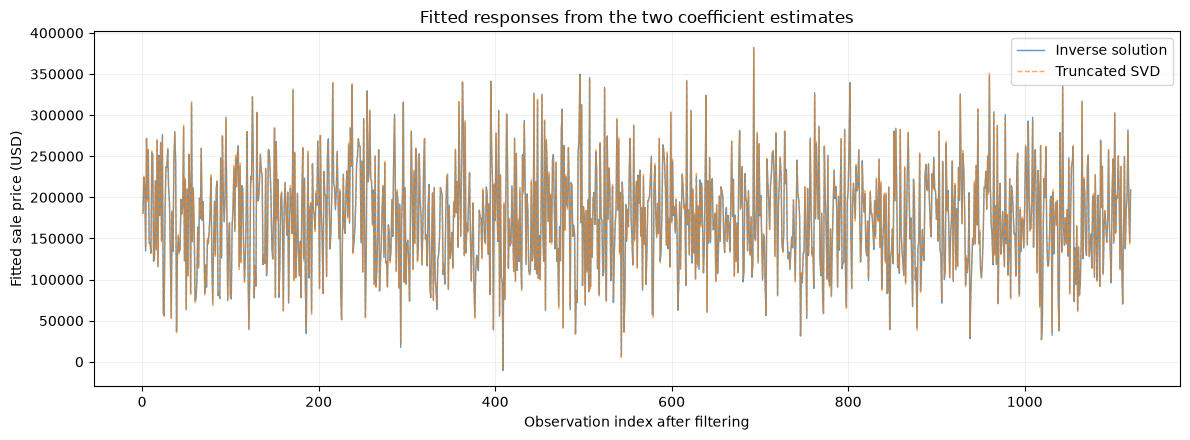

RMSE between fitted responses (USD): 1967.3683814831481


In [13]:
fig, ax = plt.subplots(figsize=(12, 4.5))
observations_q7 = np.arange(1, n_q7 + 1)
ax.plot(observations_q7, fitted_inverse_q7, color='tab:blue', alpha=0.75,
        linewidth=1, label='Inverse solution')
ax.plot(observations_q7, fitted_svd_q7, color='tab:orange', alpha=0.65,
        linewidth=1, linestyle='--', label='Truncated SVD')
ax.set(xlabel='Observation index after filtering', ylabel='Fitted sale price (USD)',
       title='Fitted responses from the two coefficient estimates')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
print('RMSE between fitted responses (USD):',
      np.sqrt(np.mean((fitted_inverse_q7 - fitted_svd_q7)**2)))

#### 7.3 — Comparing coefficients

We plot the requested natural logarithm
$\ell_i=\log|\hat\beta_i/\hat\beta_i^{SVD}|$, with indices $i=1,\ldots,16$ and names
on the horizontal axis. Large $|\ell_i|$ means a large multiplicative difference;
the sign of $\ell_i$ only indicates which coefficient has the larger absolute value.
The plot discards coefficient signs, so we also inspect the signed coefficient table.

,term,inverse,SVD,absolute_change,log_abs_ratio
1,intercept,-3.039720e+06,-0.266231,3.039719e+06,16.250666
2,LotArea,2.978147e+00,2.940153,3.799422e-02,0.012840
3,YearBuilt,6.168397e+02,612.373502,4.466176e+00,0.007267
4,GarageCars,2.125655e+04,21197.773770,5.877332e+01,0.002769
5,YrSold,8.849475e+02,-624.392417,1.509340e+03,0.348749
6,MoSold,9.837944e+02,866.645736,1.171486e+02,0.126787
7,Fireplaces,1.676336e+04,16647.231403,1.161280e+02,0.006952
8,HalfBath,2.791565e+04,28030.112433,1.144614e+02,-0.004092
9,LowQualFinSF,6.896052e+01,68.068716,8.918029e-01,0.013016
10,TotalBsmtSF,4.389619e+01,44.099044,2.028571e-01,-0.004611


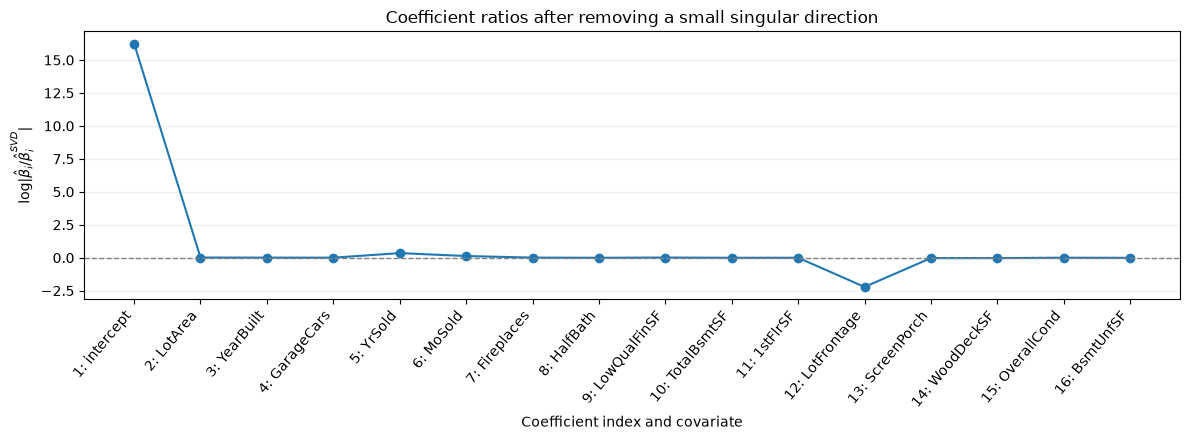

Largest absolute log ratio, including intercept: intercept
Largest absolute log ratio among predictors: LotFrontage
Largest absolute coefficient change among predictors: YrSold


In [14]:
# Leave undefined ratios as NaN.
ratio_q7 = np.full(p_q7, np.nan)
np.divide(beta_inverse_q7, beta_svd_q7, out=ratio_q7, where=(beta_svd_q7 != 0))
log_ratio_q7 = np.full(p_q7, np.nan)
np.log(np.abs(ratio_q7), out=log_ratio_q7, where=(ratio_q7 != 0) & ~np.isnan(ratio_q7))
log_ratio_q7[(ratio_q7 == 0)] = -np.inf
absolute_change_q7 = np.abs(beta_inverse_q7 - beta_svd_q7)

comparison_q7 = pd.DataFrame({
    'term': names_q7, 'inverse': beta_inverse_q7, 'SVD': beta_svd_q7,
    'absolute_change': absolute_change_q7, 'log_abs_ratio': log_ratio_q7,
}, index=np.arange(1, p_q7 + 1))
display(comparison_q7)

fig, ax = plt.subplots(figsize=(12, 4.5))
finite_q7 = np.isfinite(log_ratio_q7)
indices_q7 = np.arange(1, p_q7 + 1)
ax.plot(indices_q7[finite_q7], log_ratio_q7[finite_q7], 'o-', color='tab:blue')
ax.axhline(0, color='gray', linewidth=1, linestyle='--')
ax.set_xticks(indices_q7, [f'{i}: {name}' for i, name in zip(indices_q7, names_q7)],
              rotation=50, ha='right')
ax.set(xlabel='Coefficient index and covariate', ylabel=r'$\log|\hat\beta_i/\hat\beta_i^{SVD}|$',
       title='Coefficient ratios after removing a small singular direction')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()

print('Largest absolute log ratio, including intercept:',
      names_q7[int(np.nanargmax(np.abs(log_ratio_q7)))])
print('Largest absolute log ratio among predictors:',
      names_q7[1 + int(np.nanargmax(np.abs(log_ratio_q7[1:])))])
print('Largest absolute coefficient change among predictors:',
      names_q7[1 + int(np.argmax(absolute_change_q7[1:]))])

Including the intercept, its change is the largest: approximately
$-3.03972\times10^6$ versus $-0.266231$, with log absolute ratio about $16.2507$.
Among the actual predictors:

- `LotFrontage` has the largest multiplicative change, with log absolute ratio about
  $-2.21689$ (approximately $0.733459$ versus $6.732206$).
- `YrSold` has the largest absolute coefficient change in its original units:
  approximately $884.9475$ versus $-624.3924$; its sign also changes.

The fitted responses differ by an RMSE of about $1967.37$ dollars, despite the much
larger changes in some coefficients. The removed direction is one in which the design
maps relatively large coefficient changes to relatively small fitted-value changes.
Indeed, the right singular vector of the removed direction is approximately
$v_{16}\approx(1,\,0,\,0,\,-1/2008,\,0,\ldots,0)^\top$ (intercept and `YrSold`).
Since `YrSold` only takes values between 2006 and 2010, the column `YrSold` is almost
a constant multiple ($\approx2008$) of the intercept column, so $Zv_{16}\approx0$.
Dropping this direction is exactly why the intercept and `YrSold` change the most.
This illustrates the lecture's reason for using SVD to handle nearly dependent columns.